# 03 - Hasil dan Analisis

Notebook ini **tidak melatih model**. Ia membaca hasil notebook 01 (MosquitoSong, MosquitoSong+, checkpoint rilis) dan 02 (pembanding) lalu menyusun semua tabel, uji statistik, dan gambar untuk artikel. Cukup dijalankan dengan CPU.

| Bagian | Isi |
|---|---|
| 1-2 | Setup, pengumpulan hasil dari Input, inventaris fold |
| 3 | Gerbang pilot dan lr terpilih per fold |
| 4 | Ensemble (H4) dan himpunan metode final |
| 5 | Tabel utama vs MosquitoSong+ replikasi dan paper; F1 per kelas; MF1 per G dan kondisi test |
| 6 | Uji hipotesis: H1, keluarga H2-H4 (*corrected resampled t-test* + Wilcoxon + Holm), eksploratori attention |
| 7 | Sensitivitas kebocoran (subset bebas-kebocoran) |
| 8 | Kesimpulan per kriteria "mengungguli MosquitoSong+" |
| 9 | Variansi seed |
| 10 | Gambar: boxplot, F1 per kelas, confusion matrix, kurva validasi |
| 11 | Biaya: parameter, waktu training, latensi |

**Cara menjalankan di Kaggle:** *Add Input* dataset rekaman (untuk analisis kebocoran) dan **semua output terakhir** notebook 01 dan 02, lalu *Save & Run All* (Accelerator: None).

## 1. Setup

In [1]:
# [lib] impor-dan-konstanta
import os, re, sys, math, json, time, glob, random, shutil, platform
from types import SimpleNamespace

import numpy as np
import pandas as pd
import soundfile as sf
import tensorflow as tf
import keras
from keras import layers as L
from keras import ops

SR = 8000            # sampling rate (Hz)
TARGET = 2400        # 1 epoch = 300 ms
GAINS = (1, 1.5, 2)  # faktor volume wingbeat G pada validation/test
CLASSES = ['Ae.Aegypti_F', 'Ae.Aegypti_M', 'Ae.Albopictus_F', 'Ae.Albopictus_M',
           'An.Dirus_F', 'An.Dirus_M', 'Cx.Quin_F', 'Cx.Quin_M']   # urutan sama dengan LabelEncoder
SHORT = ['Ae.aeg F', 'Ae.aeg M', 'Ae.alb F', 'Ae.alb M', 'An.dir F', 'An.dir M', 'Cx.quin F', 'Cx.quin M']

In [2]:
WORK = '/kaggle/working' if os.path.isdir('/kaggle/working') else os.getcwd()
INPUT = os.environ.get('MOSQ_INPUT', '/kaggle/input')
os.chdir(WORK)
SEED = 42
random.seed(SEED); np.random.seed(SEED)

BASELINE, OLD = 'mosquitosong_plus', 'mosquitosong'
PAPER_MSPLUS = {'ACC': 0.918, 'MF1': 0.911}                 # Tabel 3 paper, MosquitoSong+ (noise sim.)
FAMILY_RUNS = {                                             # varian lr tiap keluarga (nama run dari notebook 02)
    'mfcc_cnn': ['mfcc_cnn_lr1e-3', 'mfcc_cnn_lr3e-4'],
    'ecapa_mfcc': ['ecapa_mfcc_lr1e-3', 'ecapa_mfcc_lr3e-4'],
    'densenet121': ['densenet121_lr3e-4', 'densenet121_lr1e-4'],
    'mosquitosong_plus_mfcc': ['mosquitosong_plus_mfcc_paper'],
}
PILOT_EPOCHS = {'mosquitosong_plus_mfcc': 100}
HYPOTHESIS = {'mfcc_cnn': 'H2', 'ecapa_mfcc': 'H2', 'densenet121': 'H2', 'mosquitosong_plus_mfcc': 'H3', 'ensemble': 'H4'}
ASP_RUN = 'densenet121_asp_sel'
RHO = 0.1                                                   # porsi test per fold untuk corrected t-test (1/10)
ALPHA = 0.05
print('Work dir:', WORK)

Work dir: /kaggle/working


Fungsi segmentasi, split, dan arsitektur model diambil dari notebook 01-02 (dipakai untuk subset bebas-kebocoran serta menghitung parameter dan latensi).

In [3]:
# [lib] segmentasi
_numbers = re.compile(r'(\d+)')


def numerical_sort(value):
    """Urutan file 'natural' (cut2 < cut10), sama dengan numericalSort di notebook rilis."""
    parts = _numbers.split(value)
    parts[1::2] = map(int, parts[1::2])
    return parts


def group_key(row):
    """Kunci kelompok rekaman: spesies_sex_umur[_LowMic] (recreate_mosquito_filename_without_noise)."""
    key = (row[0] + '_' + row[1]).strip() + '_' + row[2].strip()
    return key + '_LowMic' if row[5].strip() == 'LowMic' else key


def load_epochs(data_dir):
    """Potong setiap wav menjadi epoch 300 ms dengan hop 150 ms + jitter 0..119 sampel.
    Mengembalikan list (group_key, label, is_lowmic, epoch[2400]) dalam urutan notebook rilis."""
    out = []
    for p in sorted(os.listdir(data_dir), key=numerical_sort):
        if not p.endswith('.wav'):
            continue
        row = p.split('_')
        if row[0] == 'An.Minimus':
            continue
        x, sr = sf.read(os.path.join(data_dir, p), dtype='float32')
        assert sr == SR, f'{p}: diharapkan 8 kHz, didapat {sr}'
        label, key, low = row[0] + '_' + row[1][1], group_key(row), row[5] == 'LowMic'
        for i in range(0, len(x), TARGET // 2):
            np.random.seed(i)                       # jitter deterministik seperti notebook rilis
            shift = np.random.randint(120)
            y = x[i + shift: i + TARGET + shift]
            if len(y) == TARGET:
                out.append((key, label, low, y))
    return out


def count_per_group(epochs):
    """Jumlah epoch per kelompok rekaman (count_data)."""
    counts = {}
    for key, *_ in epochs:
        counts[key] = counts.get(key, 0) + 1
    return counts


def epoch_files(data_dir):
    """Nama file asal tiap epoch, urutan identik dengan load_epochs (untuk analisis kebocoran & EDA).
    Hanya membaca panjang file; jitter direproduksi dengan seed yang sama."""
    out = []
    for p in sorted(os.listdir(data_dir), key=numerical_sort):
        if not p.endswith('.wav') or p.split('_')[0] == 'An.Minimus':
            continue
        n = sf.info(os.path.join(data_dir, p)).frames
        for i in range(0, n, TARGET // 2):
            np.random.seed(i)
            if i + np.random.randint(120) + TARGET <= n:
                out.append(p)
    return out

In [4]:
# [lib] split-fold
# Kuota test per kelompok (hanya mikrofon low-cost), disalin apa adanya dari notebook rilis.
COUNT_TEST_LOW = {
    'Cx.Quin_1F_14D_LowMic': 97, 'Ae.Aegypti_1F_21D_LowMic': 19,
    'An.Dirus_1M_14D_LowMic': 30, 'An.Dirus_1F_14D_LowMic': 34,
    'Ae.Aegypti_1M_21D_LowMic': 39, 'Ae.Albopictus_1F_7D_LowMic': 51,
    'Ae.Albopictus_1M_7D_LowMic': 46, 'Cx.Quin_1M_14D_LowMic': 72,
    'Ae.Aegypti_1F_5D_LowMic': 64, 'Ae.Albopictus_1F_14D_LowMic': 43,
    'Ae.Albopictus_1M_14D_LowMic': 57, 'Ae.Aegypti_1M_5D_LowMic': 48,
}


def split_fold(epochs, totals, fold):
    """Port 1:1 split_data(): epoch tiap kelompok dibagi kronologis menjadi 10 potongan.
    Potongan k -> validation, potongan k+1 -> test (LowMic saja, dibatasi kuota), sisanya -> train."""
    test_index = -1 if fold == 9 else fold
    seen = {k: 0 for k in totals}
    low_count = {k: 0 for k in COUNT_TEST_LOW}
    sets = {s: ([], []) for s in ('train', 'val', 'test')}
    for key, label, low, y in epochs:
        cur = seen[key]
        seen[key] += 1
        chunk = math.floor(totals[key] * 0.1)
        if fold * chunk <= cur < (fold + 1) * chunk:
            dst = 'val'
        elif (test_index + 1) * chunk <= cur < (test_index + 2) * chunk:
            if low and low_count[key] < COUNT_TEST_LOW[key]:
                low_count[key] += 1
                dst = 'test'
            else:
                continue                            # sisa potongan test tidak dipakai
        else:
            dst = 'train'
        sets[dst][0].append(y)
        sets[dst][1].append(label)
    return {s: (np.stack(X).astype(np.float32), np.array(Y)) for s, (X, Y) in sets.items()}


def encode(labels):
    idx = {c: i for i, c in enumerate(CLASSES)}
    return np.array([idx[l] for l in labels], dtype=np.int64)

In [5]:
# [lib] model-mosquitosong
def mosquitosong(n_classes=8, input_len=2400):
    """MosquitoSong (Fig. 2 kiri): down-sampling dengan max-pool."""
    inp = L.Input((input_len, 1))
    x = L.Conv1D(32, 350, strides=4, activation='relu')(inp)
    x = L.MaxPooling1D(4, strides=4)(x)
    x = L.Conv1D(32, 100, strides=1, activation='relu')(x)
    x = L.MaxPooling1D(3, strides=3)(x)
    x = L.Dropout(0.5)(x)
    x = L.Flatten()(x)
    x = L.Dense(256, activation='relu')(x)
    x = L.Dense(128, activation='relu')(x)
    out = L.Dense(n_classes, activation='softmax', dtype='float32')(x)
    return keras.Model(inp, out, name='MosquitoSong')


def mosquitosong_plus(n_classes=8, input_len=2400):
    """MosquitoSong+ (Fig. 2 kanan): tiga conv bertingkat sebagai down-sampling yang dipelajari."""
    inp = L.Input((input_len, 1))
    x = L.Conv1D(32, 100, strides=4, activation='relu')(inp)
    x = L.Conv1D(32, 64, strides=4, activation='relu')(x)
    x = L.Conv1D(64, 64, strides=3, activation='relu')(x)
    x = L.MaxPooling1D(3, strides=3)(x)
    x = L.Dropout(0.5)(x)
    x = L.Flatten()(x)
    x = L.Dense(256, activation='relu')(x)
    x = L.Dense(128, activation='relu')(x)
    out = L.Dense(n_classes, activation='softmax', dtype='float32')(x)
    return keras.Model(inp, out, name='MosquitoSongPlus')


MODELS = {'mosquitosong': mosquitosong, 'mosquitosong_plus': mosquitosong_plus}

In [6]:
# [lib] training-per-fold
DEFAULT_CFG = dict(model='mosquitosong_plus', fold=0, epochs=1000, batch=64, lr=1e-4, seed=42,
                   recipe='paper', patience=0, tag='', precision='fp32', no_noise_aug=False, pretrained=True,
                   data='data', out='runs', log_every=10, ckpt_every=10, deadline=None, pause_at=0, max_train=0)
PRED_BATCH = 256          # batch inferensi (cukup kecil untuk DenseNet121 128x128 di T4)
PRETRAINED_MODELS = set() # model yang menerima argumen pretrained=... (diisi sel DenseNet121)


def oversample(X, y, random_state=42):
    """RandomOverSampler(sampling_strategy='all', random_state=42) seperti notebook rilis;
    fallback numpy setara bila imbalanced-learn tidak terpasang."""
    try:
        from imblearn.over_sampling import RandomOverSampler
        return RandomOverSampler(sampling_strategy='all', random_state=random_state).fit_resample(X, y)
    except ImportError:
        rng = np.random.default_rng(random_state)
        n_max = np.bincount(y).max()
        idx = np.concatenate([np.concatenate([np.where(y == c)[0], rng.choice(np.where(y == c)[0], n_max - (y == c).sum())])
                              for c in np.unique(y)])
        return X[idx], y[idx]


def setup_device(precision):
    for gpu in tf.config.list_physical_devices('GPU'):
        try:
            tf.config.experimental.set_memory_growth(gpu, True)
        except RuntimeError:
            pass                                    # GPU sudah diinisialisasi (fold kedua in-process)
    keras.mixed_precision.set_global_policy({'bf16': 'mixed_bfloat16', 'fp16': 'mixed_float16'}.get(precision, 'float32'))
    gpus = tf.config.list_physical_devices('GPU')
    return 'GPU:' + ','.join(tf.config.experimental.get_device_details(g).get('device_name', '?') for g in gpus) \
        if gpus else 'CPU:' + (platform.processor() or platform.machine())


def build_model(name, pretrained=True):
    fn = MODELS[name]
    return fn(len(CLASSES), pretrained=pretrained) if name in PRETRAINED_MODELS else fn(len(CLASSES))


def save_checkpoint(ckpt_dir, model, rng, state):
    """Checkpoint tengah-fold: bobot terakhir + state optimizer + state RNG augmentasi + histori.
    Semua file ditulis lewat nama sementara lalu diganti; state.json ditulis terakhir (penanda checkpoint valid)."""
    os.makedirs(ckpt_dir, exist_ok=True)
    model.save_weights(os.path.join(ckpt_dir, 'last.tmp.weights.h5'))
    os.replace(os.path.join(ckpt_dir, 'last.tmp.weights.h5'), os.path.join(ckpt_dir, 'last.weights.h5'))
    opt = {f'v{i}': keras.ops.convert_to_numpy(v) for i, v in enumerate(model.optimizer.variables)}
    np.savez(os.path.join(ckpt_dir, 'optimizer.tmp.npz'), **opt)
    os.replace(os.path.join(ckpt_dir, 'optimizer.tmp.npz'), os.path.join(ckpt_dir, 'optimizer.npz'))
    with open(os.path.join(ckpt_dir, 'state.tmp.json'), 'w') as f:
        json.dump({**state, 'rng': rng.bit_generator.state}, f, default=str)
    os.replace(os.path.join(ckpt_dir, 'state.tmp.json'), os.path.join(ckpt_dir, 'state.json'))


def load_checkpoint(ckpt_dir, model, rng):
    with open(os.path.join(ckpt_dir, 'state.json')) as f:
        state = json.load(f)
    model.optimizer.build(model.trainable_variables)   # bangun optimizer dulu agar bobotnya bisa diisi
    model.load_weights(os.path.join(ckpt_dir, 'last.weights.h5'))
    saved = np.load(os.path.join(ckpt_dir, 'optimizer.npz'))
    if len(saved.files) == len(model.optimizer.variables):
        for i, v in enumerate(model.optimizer.variables):
            v.assign(saved[f'v{i}'])
    elif state['epoch'] > 0:                           # jeda di epoch 0: belum ada state optimizer
        print('Peringatan: state optimizer tidak cocok, optimizer dimulai ulang', flush=True)
    rng.bit_generator.state = state.pop('rng')
    return state


def run_fold(cfg):
    """Latih + evaluasi satu (model, fold). Artefak: runs/<nama>/fold<k>/
    best.weights.h5, history.csv, preds.npz (probabilitas test + validation), config.json (penanda fold lengkap).
    Selama training, ckpt/ diperbarui tiap `ckpt_every` epoch. Fold dijeda (checkpoint disimpan) bila
    `deadline` (waktu absolut) terlewati atau epoch mencapai `pause_at` (pilot); sesi berikutnya melanjutkan."""
    a = SimpleNamespace(**{**DEFAULT_CFG, **cfg})
    run_name = a.model + (f'_{a.tag}' if a.tag else '')
    out_dir = os.path.join(a.out, run_name, f'fold{a.fold}')
    ckpt_dir = os.path.join(out_dir, 'ckpt')
    os.makedirs(out_dir, exist_ok=True)
    seed = a.seed + a.fold
    keras.utils.set_random_seed(seed)
    device = setup_device(a.precision)
    rng = np.random.default_rng(seed)

    epochs_ = load_epochs(os.path.join(a.data, 'mosquito_recordings'))
    noise, noise_names = load_noise(os.path.join(a.data, 'environmental_noise_recordings'))
    s = split_fold(epochs_, count_per_group(epochs_), a.fold)
    Xtr, ytr = oversample(s['train'][0], encode(s['train'][1]))
    Xva, yva = s['val'][0], encode(s['val'][1])
    Xte, yte = s['test'][0], encode(s['test'][1])
    if a.max_train:                                     # hanya untuk uji cepat lokal
        sub = np.random.default_rng(0).choice(len(ytr), min(a.max_train, len(ytr)), replace=False)
        Xtr, ytr = Xtr[sub], ytr[sub]

    va = make_noisy_set(Xva, 2500, noise)               # validation: noise overlay G=1,1.5,2 (seed 2500)
    Xva_all, yva_all = np.concatenate([va[g] for g in GAINS])[..., None], np.tile(yva, len(GAINS))

    noise_aug = a.model != 'mosquitosong' and not a.no_noise_aug   # MosquitoSong lama: tanpa noise aug
    model = build_model(a.model, a.pretrained)
    steps = int(np.ceil(len(ytr) / a.batch)) * a.epochs
    lr = keras.optimizers.schedules.CosineDecay(a.lr, steps, alpha=0.01) if a.recipe in ('fast', 'finetune') else a.lr
    model.compile(optimizer=keras.optimizers.Adam(lr), loss='sparse_categorical_crossentropy', metrics=['accuracy'])

    hist, best, best_ep, start_ep, elapsed0 = [], np.inf, -1, 0, 0.0
    weights_path = os.path.join(out_dir, 'best.weights.h5')
    if os.path.exists(os.path.join(ckpt_dir, 'state.json')):          # lanjutkan fold yang terjeda
        st = load_checkpoint(ckpt_dir, model, rng)
        hist, best, best_ep, start_ep, elapsed0 = st['hist'], st['best'], st['best_ep'], st['epoch'], st['elapsed']
        print(f'[{run_name} f{a.fold}] resume dari checkpoint: epoch {start_ep}, best@{best_ep}', flush=True)
    t0 = time.time() - elapsed0

    def state(epoch_done):
        return dict(epoch=epoch_done, hist=hist, best=best, best_ep=best_ep, elapsed=time.time() - t0)

    def pause(ep, why):
        save_checkpoint(ckpt_dir, model, rng, state(ep))
        print(f'[{run_name} f{a.fold}] dijeda di epoch {ep} ({why}); dilanjutkan dari checkpoint', flush=True)
        return {'status': 'paused', 'epoch': ep}

    print(f'[{run_name} f{a.fold}] device={device} lr={a.lr:g} train={len(ytr)} val={len(yva_all)} test={len(yte)} '
          f'params={model.count_params():,}', flush=True)
    for ep in range(start_ep, a.epochs):
        if a.pause_at and ep >= a.pause_at:
            return pause(ep, f'pilot {a.pause_at} epoch')
        if a.deadline and time.time() > a.deadline:
            return pause(ep, 'batas waktu sesi')
        Xa = augment_batch(Xtr, rng, noise, noise_aug=noise_aug)[..., None]
        h = model.fit(Xa, ytr, batch_size=a.batch, epochs=1, shuffle=True, verbose=0)
        vl, vacc = model.evaluate(Xva_all, yva_all, batch_size=PRED_BATCH, verbose=0)
        hist.append(dict(epoch=ep + 1, loss=h.history['loss'][0], acc=h.history['accuracy'][0],
                         val_loss=vl, val_acc=vacc, t=time.time() - t0))
        if vl < best:                                   # pemilihan model: val loss minimum
            best, best_ep = vl, ep + 1
            model.save_weights(weights_path)
        if (ep + 1) % a.log_every == 0 or ep == start_ep:
            print(f'[{run_name} f{a.fold}] ep {ep+1}/{a.epochs} loss {h.history["loss"][0]:.4f} '
                  f'val_loss {vl:.4f} val_acc {vacc:.4f} best@{best_ep} ({time.time()-t0:.0f}s)', flush=True)
        if a.patience and ep + 1 - best_ep >= a.patience:
            print(f'[{run_name} f{a.fold}] early stop at epoch {ep+1}', flush=True)
            break
        if a.ckpt_every and (ep + 1) % a.ckpt_every == 0:
            save_checkpoint(ckpt_dir, model, rng, state(ep + 1))
    pd.DataFrame(hist).to_csv(os.path.join(out_dir, 'history.csv'), index=False)

    model.load_weights(weights_path)                    # test: protokol rilis (noisy + clean, tiap G)
    te_noisy, te_clean = make_noisy_set(Xte, 0, noise), make_clean_set(Xte)
    preds = {'y': yte, 'y_val': yva_all, 'val': model.predict(Xva_all, batch_size=PRED_BATCH, verbose=0)}
    for g in GAINS:
        preds[f'noisy_G{g}'] = model.predict(te_noisy[g][..., None], batch_size=PRED_BATCH, verbose=0)
        preds[f'clean_G{g}'] = model.predict(te_clean[g][..., None], batch_size=PRED_BATCH, verbose=0)
    np.savez_compressed(os.path.join(out_dir, 'preds.npz'), **preds)
    acc = float(np.mean([(preds[f'{c}_G{g}'].argmax(1) == yte).mean() for c in ('noisy', 'clean') for g in GAINS]))

    meta = dict(vars(a), run=run_name, seed_effective=seed, best_epoch=best_ep, best_val_loss=best,
                epochs_run=len(hist), resumed_from_epoch=start_ep, n_train_balanced=len(ytr), n_val=len(yva),
                n_test=len(yte), noise_aug=noise_aug, noise_files=noise_names, classes=CLASSES, device=device,
                params=model.count_params(), tf=tf.__version__, keras=keras.__version__, numpy=np.__version__,
                python=platform.python_version(), train_time_s=time.time() - t0, test_acc_all=acc)
    with open(os.path.join(out_dir, 'config.json'), 'w') as f:      # ditulis terakhir = penanda fold lengkap
        json.dump(meta, f, indent=2, default=str)
    shutil.rmtree(ckpt_dir, ignore_errors=True)        # checkpoint tidak diperlukan lagi
    print(f'[{run_name} f{a.fold}] done. best epoch {best_ep}, test ACC {acc:.3f}, '
          f'{(time.time()-t0)/60:.1f} min', flush=True)
    return {'status': 'done', **meta}

In [7]:
# [lib] pembanding-blok-umum
def conv_bn(x, ch, k, s=1, d=1, act=True):
    x = L.Conv1D(ch, k, strides=s, dilation_rate=d, padding='same', use_bias=False)(x)
    x = L.BatchNormalization()(x)
    return L.ReLU()(x) if act else x


def head(x, n_classes):
    """Kepala klasifikasi bersama: dropout 0,5 -> FC 128 -> softmax (fp32 walau mixed precision)."""
    x = L.Dropout(0.5)(x)
    x = L.Dense(128, activation='relu')(x)
    return L.Dense(n_classes, activation='softmax', dtype='float32')(x)

In [8]:
# [lib] fitur-spektral
class MFCC(L.Layer):
    """MFCC dihitung di dalam model (tf.signal): selalu dari waveform yang sudah diaugmentasi, ikut berjalan di GPU.
    Frame 512 (64 ms, 15,6 Hz/bin), hop 64 (8 ms) -> 30 frame; 64 pita mel 100-4000 Hz; 40 koefisien c1..c40.
    c0 (energi) dibuang sehingga fitur tidak peka augmentasi amplitudo -12..12 dB."""

    def __init__(self, n_mfcc=40, frame=512, hop=64, n_mels=64, fmin=100.0, fmax=4000.0, **kw):
        kw.setdefault('dtype', 'float32')           # STFT selalu fp32 walau mixed precision
        super().__init__(**kw)
        self.n_mfcc, self.frame, self.hop, self.n_mels, self.fmin, self.fmax = n_mfcc, frame, hop, n_mels, fmin, fmax

    def call(self, x):
        x = tf.cast(tf.squeeze(x, -1), tf.float32)
        spec = tf.abs(tf.signal.stft(x, self.frame, self.hop, self.frame))                 # (B, 30, 257)
        mel = tf.signal.linear_to_mel_weight_matrix(self.n_mels, self.frame // 2 + 1, SR, self.fmin, self.fmax)
        logmel = tf.math.log(tf.tensordot(spec, mel, 1) + 1e-6)                            # (B, 30, 64)
        return tf.signal.mfccs_from_log_mel_spectrograms(logmel)[..., 1:self.n_mfcc + 1]  # (B, 30, 40)

    def compute_output_shape(self, shape):
        return (shape[0], (shape[1] - self.frame) // self.hop + 1, self.n_mfcc)


class LogSpectrogram(L.Layer):
    """Log-spektrogram sebagai 'gambar' untuk CNN ImageNet: STFT 512 / hop 32 -> 60 frame x 251 bin (±100-4000 Hz;
    6 bin terbawah dibuang karena berisi rumble < 100 Hz yang mendominasi energi, lihat EDA 5.6), log-magnitude,
    standardisasi per sampel, frekuensi rendah di bawah, resize 128 x 128, diulang ke 3 kanal."""

    def __init__(self, frame=512, hop=32, size=128, min_bin=6, **kw):
        kw.setdefault('dtype', 'float32')
        super().__init__(**kw)
        self.frame, self.hop, self.size, self.min_bin = frame, hop, size, min_bin

    def call(self, x):
        x = tf.cast(tf.squeeze(x, -1), tf.float32)
        s = tf.abs(tf.signal.stft(x, self.frame, self.hop, self.frame))[..., self.min_bin:]   # (B, 60, 251)
        s = tf.math.log(s + 1e-6)
        mu = tf.reduce_mean(s, axis=[1, 2], keepdims=True)
        sd = tf.math.reduce_std(s, axis=[1, 2], keepdims=True) + 1e-6
        s = tf.reverse(tf.transpose((s - mu) / sd, [0, 2, 1]), axis=[1])[..., None]          # (B, 251, 60, 1)
        s = tf.image.resize(s, (self.size, self.size))
        return tf.repeat(s, 3, axis=-1)                                                       # (B, 128, 128, 3)

    def compute_output_shape(self, shape):
        return (shape[0], self.size, self.size, 3)

In [9]:
# [lib] pembanding-ecapa-mfcc
def se_res2_block(x, ch, k, d, scale=4, se_bottleneck=64):
    """SE-Res2Net: channel dibagi `scale` grup, konvolusi hierarkis (multi-skala), SE, residual."""
    res = x
    splits = ops.split(conv_bn(x, ch, 1), scale, axis=-1)
    outs, prev = [splits[0]], None
    for i in range(1, scale):
        s = splits[i] if prev is None else L.Add()([splits[i], prev])
        prev = conv_bn(s, ch // scale, k, d=d)
        outs.append(prev)
    h = conv_bn(L.Concatenate()(outs), ch, 1)
    w = L.GlobalAveragePooling1D(keepdims=True)(h)
    w = L.Conv1D(ch, 1, activation='sigmoid')(L.Conv1D(se_bottleneck, 1, activation='relu')(w))
    return L.Add()([L.Multiply()([h, w]), res])


class AttentiveStatsPool(L.Layer):
    """Attentive Statistics Pooling: bobot per posisi & per channel -> [mean berbobot ‖ std berbobot]."""

    def __init__(self, bottleneck=64, **kw):
        super().__init__(**kw)
        self.bottleneck = bottleneck

    def build(self, shape):
        ch = shape[-1]
        self.att1 = L.Conv1D(self.bottleneck, 1, activation='tanh')
        self.att2 = L.Conv1D(ch, 1)
        self.att1.build((None, None, ch * 3))
        self.att2.build((None, None, self.bottleneck))

    def call(self, x):
        x = ops.cast(x, 'float32')
        mu = ops.mean(x, axis=1, keepdims=True)
        sd = ops.sqrt(ops.clip(ops.var(x, axis=1, keepdims=True), 1e-5, 1e5))
        t = ops.shape(x)[1]
        ctx = ops.concatenate([x, ops.repeat(mu, t, axis=1), ops.repeat(sd, t, axis=1)], -1)
        a = ops.softmax(ops.cast(self.att2(self.att1(ops.cast(ctx, self.compute_dtype))), 'float32'), axis=1)
        m = ops.sum(a * x, axis=1)
        s = ops.sqrt(ops.clip(ops.sum(a * x * x, axis=1) - m * m, 1e-5, 1e5))
        return ops.concatenate([m, s], -1)

    def compute_output_shape(self, shape):
        return (shape[0], 2 * shape[-1])


def ecapa_mfcc(n_classes=8, input_len=2400, ch=96):
    """ECAPA-TDNN dengan input MFCC seperti paper aslinya (Desplanques et al., 2020), versi kecil."""
    inp = L.Input((input_len, 1))
    x = L.BatchNormalization()(MFCC()(inp))         # 30 frame x 40 koefisien, dinormalisasi per koefisien
    x = conv_bn(x, ch, 5)                           # 30 x 96
    b1 = se_res2_block(x, ch, 3, 2)
    b2 = se_res2_block(b1, ch, 3, 3)
    b3 = se_res2_block(b2, ch, 3, 4)
    x = conv_bn(L.Concatenate()([b1, b2, b3]), 3 * ch, 1)   # Multi-layer Feature Aggregation
    x = L.BatchNormalization()(AttentiveStatsPool()(x))     # 576
    return keras.Model(inp, head(x, n_classes), name='ECAPA_MFCC')

In [10]:
# [lib] pembanding-mfcc
def mfcc_cnn(n_classes=8, input_len=2400):
    """Pembanding 'fitur beda': hanya MFCC (30 frame x 40 koefisien) -> CNN 1D kecil."""
    inp = L.Input((input_len, 1))
    x = L.BatchNormalization()(MFCC()(inp))         # normalisasi tiap koefisien
    x = conv_bn(conv_bn(x, 64, 3), 64, 3)
    x = L.MaxPooling1D(2)(x)                        # 15 frame
    x = conv_bn(conv_bn(x, 128, 3), 128, 3)
    x = L.GlobalAveragePooling1D()(x)
    return keras.Model(inp, head(x, n_classes), name='MFCC_CNN')


def mosquitosong_plus_mfcc(n_classes=8, input_len=2400):
    """Fusion: cabang waveform MosquitoSong+ (utuh sampai Flatten) + cabang statistik MFCC (mean & std tiap koefisien)."""
    inp = L.Input((input_len, 1))
    x = L.Conv1D(32, 100, strides=4, activation='relu')(inp)
    x = L.Conv1D(32, 64, strides=4, activation='relu')(x)
    x = L.Conv1D(64, 64, strides=3, activation='relu')(x)
    x = L.Flatten()(L.Dropout(0.5)(L.MaxPooling1D(3, strides=3)(x)))            # 448
    m = MFCC()(inp)
    m = L.Concatenate()([ops.mean(m, axis=1), ops.std(m, axis=1)])              # 80
    m = L.Dense(64, activation='relu')(L.BatchNormalization()(m))
    h = L.Concatenate()([x, m])
    h = L.Dense(128, activation='relu')(L.Dense(256, activation='relu')(h))
    out = L.Dense(n_classes, activation='softmax', dtype='float32')(h)
    return keras.Model(inp, out, name='MosquitoSongPlus_MFCC')


MODELS.update({'mfcc_cnn': mfcc_cnn, 'ecapa_mfcc': ecapa_mfcc, 'mosquitosong_plus_mfcc': mosquitosong_plus_mfcc})

In [11]:
# [lib] pembanding-densenet121
def densenet121_spec(n_classes=8, input_len=2400, pretrained=True, asp=False):
    """DenseNet121 (bobot ImageNet) pada log-spektrogram 128 x 128 x 3.
    asp=False: global average pooling (standar). asp=True: ablation attention, peta fitur terakhir 4 x 4 x 1024
    diperlakukan sebagai 16 posisi waktu-frekuensi lalu diringkas dengan Attentive Statistics Pooling."""
    inp = L.Input((input_len, 1))
    x = LogSpectrogram()(inp)
    base = keras.applications.DenseNet121(include_top=False, weights='imagenet' if pretrained else None,
                                          input_shape=(128, 128, 3))
    f = base(x)                                     # (4, 4, 1024)
    if asp:
        f = L.BatchNormalization()(AttentiveStatsPool()(L.Reshape((16, 1024))(f)))   # 2048
    else:
        f = L.GlobalAveragePooling2D()(f)           # 1024
    return keras.Model(inp, head(f, n_classes), name='DenseNet121_ASP' if asp else 'DenseNet121')


def densenet121(n_classes=8, input_len=2400, pretrained=True):
    return densenet121_spec(n_classes, input_len, pretrained, asp=False)


def densenet121_asp(n_classes=8, input_len=2400, pretrained=True):
    return densenet121_spec(n_classes, input_len, pretrained, asp=True)


MODELS.update({'densenet121': densenet121, 'densenet121_asp': densenet121_asp})
PRETRAINED_MODELS.update({'densenet121', 'densenet121_asp'})

## 2. Mengumpulkan Hasil

Semua fold lengkap dari Input disalin ke `runs/`. Bila satu run ada di beberapa versi output, versi lengkap yang dipakai.

In [12]:
def find_dir(name):
    """Cari folder berisi wav di INPUT (atau MOSQ_DATA untuk uji lokal); zip mentah juga didukung."""
    roots = [r for r in (os.environ.get('MOSQ_DATA', ''), INPUT, WORK) if r and os.path.isdir(r)]
    for r in roots:
        for d in glob.glob(os.path.join(r, '**', name), recursive=True):
            if os.path.isdir(d) and glob.glob(os.path.join(d, '*.wav')):
                return d
    import zipfile
    for r in roots:
        for z in glob.glob(os.path.join(r, '**', f'*{name}*.zip'), recursive=True):
            zipfile.ZipFile(z).extractall(os.path.join(WORK, 'data_extracted'))
            return find_dir(name)
    raise FileNotFoundError(f'Folder {name}/ tidak ditemukan. Sudah Add Input dataset?')


os.makedirs('data', exist_ok=True)
for name in ('mosquito_recordings', 'environmental_noise_recordings'):
    src_dir, dst = find_dir(name), os.path.join('data', name)
    if not os.path.exists(dst):
        os.symlink(src_dir, dst)
    print(f'{name}: {src_dir} ({len(glob.glob(dst + "/*.wav"))} wav)')


# Resume dari output versi sebelumnya / notebook lain (di-Add sebagai Input):
#   fold lengkap (config.json + preds.npz) -> dipakai apa adanya
#   fold terjeda (ckpt/state.json)        -> dilanjutkan dari epoch checkpoint terbaru
def _ckpt_epoch(d):
    try:
        return json.load(open(os.path.join(d, 'ckpt', 'state.json')))['epoch']
    except (OSError, ValueError, KeyError):
        return -1


best_src = {}
for fold_dir_ in glob.glob(os.path.join(INPUT, '**', 'runs', '*', 'fold*'), recursive=True):
    if not os.path.isdir(fold_dir_):
        continue
    rel = os.path.join('runs', *fold_dir_.split(os.sep)[-2:])
    done = os.path.exists(os.path.join(fold_dir_, 'config.json')) and os.path.exists(os.path.join(fold_dir_, 'preds.npz'))
    score = 10**9 if done else _ckpt_epoch(fold_dir_)
    if score >= 0 and score > best_src.get(rel, (None, -1))[1]:
        best_src[rel] = (fold_dir_, score)
complete, paused = [], []
for rel, (fold_dir_, score) in sorted(best_src.items()):
    if os.path.exists(os.path.join(rel, 'config.json')) or (score < 10**9 and _ckpt_epoch(rel) >= score):
        continue                                            # versi lokal sudah sama/lebih baru
    shutil.copytree(fold_dir_, rel, dirs_exist_ok=True)
    (complete if score == 10**9 else paused).append(rel if score == 10**9 else f'{rel} (epoch {score})')
print(f'Resume dari input: {len(complete)} fold lengkap, {len(paused)} fold terjeda', paused)

mosquito_recordings: /kaggle/input/datasets/sirojmunir/mosquito/mosquito_recordings/mosquito_recordings (1324 wav)
environmental_noise_recordings: /kaggle/input/datasets/sirojmunir/mosquito/environmental_noise_recordings/environmental_noise_recordings (12 wav)
Resume dari input: 106 fold lengkap, 0 fold terjeda []


In [13]:
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_recall_fscore_support
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display

RUN_LABELS = {'mosquitosong_plus': 'MosquitoSong+', 'mosquitosong': 'MosquitoSong',
              'released_mosquitosong': 'Checkpoint rilis (MosquitoSong)',
              'mfcc_cnn': 'MFCC-CNN', 'ecapa_mfcc': 'ECAPA-MFCC', 'densenet121': 'DenseNet121-spektrogram',
              'mosquitosong_plus_mfcc': 'MosquitoSong+ + MFCC', 'densenet121_asp': 'DenseNet121-ASP',
              'ensemble': 'Ensemble',
              # hasil screening run pertama (tidak dilanjutkan)
              'mosquitosong_plus_fast': 'MosquitoSong+ (resep cepat)', 'vovnet_ese': 'VoVNet-eSE (raw)',
              'ecapa_tdnn': 'ECAPA-TDNN (raw)', 'conv_transformer': 'Conv-Transformer (raw)'}


def LBL(r):
    for k in sorted(RUN_LABELS, key=len, reverse=True):
        if r == k:
            return RUN_LABELS[k]
        if r.startswith(k + '_'):
            return f'{RUN_LABELS[k]} [{r[len(k) + 1:]}]'
    return r


def load_run(run):
    """Prediksi per fold yang lengkap: list dict {fold, y, noisy_G1, clean_G1, ..., (val, y_val)}."""
    out = []
    for p in sorted(glob.glob(f'runs/{run}/fold*/preds.npz')):
        if os.path.exists(os.path.join(os.path.dirname(p), 'config.json')):
            d = dict(np.load(p)); d['fold'] = int(os.path.basename(os.path.dirname(p))[4:]); out.append(d)
    return sorted(out, key=lambda d: d['fold'])


def collect(folds, gains=GAINS, include_clean=True, include_noisy=True, masks=None):
    """Gabungkan (y_true, y_pred) dari fold-fold untuk G/kondisi yang dipilih; masks = {fold: bool[n_test]} opsional."""
    yt, yp = [], []
    for d in folds:
        m = slice(None) if masks is None else masks[d['fold']]
        for g in gains:
            for cond, use in (('noisy', include_noisy), ('clean', include_clean)):
                if use:
                    yt.append(d['y'][m]); yp.append(d[f'{cond}_G{g}'][m].argmax(1))
    return np.concatenate(yt), np.concatenate(yp)


def summary(y, p):
    f1 = precision_recall_fscore_support(y, p, labels=range(8), zero_division=0)[2]
    return {'ACC': accuracy_score(y, p), 'MF1': f1_score(y, p, labels=range(8), average='macro', zero_division=0),
            'N': len(y), **{f'F1 {c}': v for c, v in zip(SHORT, f1)}}


def per_fold(folds, masks=None):
    rows = []
    for d in folds:
        s = summary(*collect([d], masks=masks)); s.pop('N'); rows.append({'fold': d['fold'], **s})
    return pd.DataFrame(rows).set_index('fold')


def confmat(folds, gains=GAINS, normalize=True):
    y, p = collect(folds, gains=gains)
    return confusion_matrix(y, p, labels=range(8), normalize='true' if normalize else None)


def hist(run, fold): return pd.read_csv(f'runs/{run}/fold{fold}/history.csv')
def cfgj(run, fold): return json.load(open(f'runs/{run}/fold{fold}/config.json'))


pd.set_option('display.width', 220); pd.set_option('display.max_columns', 40); os.makedirs('figures', exist_ok=True)

In [14]:
pd.set_option('display.width', 220); pd.set_option('display.max_columns', 40)


def run_complete_folds(run):
    return sorted(int(os.path.basename(d)[4:]) for d in glob.glob(f'runs/{run}/fold*')
                  if os.path.exists(f'{d}/config.json') and os.path.exists(f'{d}/preds.npz'))


all_runs = sorted(os.path.basename(d) for d in glob.glob('runs/*'))
inventory = pd.DataFrame({f'fold {f}': ['✓' if f in run_complete_folds(r) else '–' for r in all_runs] for f in range(10)},
                         index=all_runs)
inventory['lengkap'] = [f'{len(run_complete_folds(r))}/10' for r in all_runs]
inventory

,fold 0,fold 1,fold 2,fold 3,fold 4,fold 5,fold 6,fold 7,fold 8,fold 9,lengkap
densenet121_asp_sel,✓,✓,✓,✓,✓,✓,✓,✓,✓,✓,10/10
densenet121_lr1e-4,✓,✓,✓,✓,✓,✓,✓,✓,✓,✓,10/10
densenet121_lr3e-4,✓,✓,✓,✓,✓,✓,✓,✓,✓,✓,10/10
ecapa_mfcc_lr1e-3,✓,✓,✓,✓,✓,✓,✓,✓,✓,✓,10/10
ecapa_mfcc_lr3e-4,✓,✓,✓,✓,✓,✓,✓,✓,✓,✓,10/10
mfcc_cnn_lr1e-3,✓,✓,✓,✓,✓,✓,✓,✓,✓,✓,10/10
mfcc_cnn_lr3e-4,✓,✓,✓,✓,✓,✓,✓,✓,✓,✓,10/10
mosquitosong,✓,✓,✓,✓,✓,✓,✓,✓,✓,✓,10/10
mosquitosong_plus,✓,✓,✓,✓,✓,✓,✓,✓,✓,✓,10/10
mosquitosong_plus_mfcc_paper,✓,✓,✓,✓,✓,✓,✓,✓,✓,✓,10/10


## 3. Gerbang Pilot dan Pemilihan lr

Gerbang ditetapkan sebelum eksperimen: model lanjut ke 10 fold bila val acc terbaik fold 0 ≥ val acc MosquitoSong+ fold 0 (MS+ + MFCC dibandingkan pada 100 epoch pertama). Model yang gagal dilaporkan sebagai hasil negatif. Pada keluarga dengan dua lr, setiap fold memakai varian dengan val loss minimum **di fold itu sendiri**.

In [15]:
def selected_run_name(fam, fold):
    """Varian lr dengan val loss minimum di fold itu sendiri (None bila belum semua varian lengkap)."""
    cands = FAMILY_RUNS[fam]
    if not all(fold in run_complete_folds(r) for r in cands):
        return None
    return min(cands, key=lambda r: cfgj(r, fold)['best_val_loss'])


def best_val_acc(h, max_epoch=None):
    h = h[h.epoch <= max_epoch] if max_epoch else h
    return float(h.val_acc.loc[h.val_loss.idxmin()])


# Gerbang pilot (fold 0): val acc terbaik >= val acc MosquitoSong+ fold 0 (resep paper: s.d. epoch yang sama)
gate_rows = []
for fam, runs in FAMILY_RUNS.items():
    pe = PILOT_EPOCHS.get(fam)
    ref = best_val_acc(hist(BASELINE, 0), pe) if 0 in run_complete_folds(BASELINE) else np.nan
    accs = {r: best_val_acc(hist(r, 0), pe) for r in runs if 0 in run_complete_folds(r)}
    best = max(accs, key=accs.get) if accs else None
    gate_rows.append({'keluarga': fam, 'acuan MS+ fold 0': ref, 'varian terbaik': best,
                      'val acc pilot': accs.get(best, np.nan),
                      'lolos': (accs[best] >= ref) if best and not np.isnan(ref) else None,
                      'fold lengkap (varian terpilih)': sum(selected_run_name(fam, f) is not None for f in range(10))})
GATE = pd.DataFrame(gate_rows).set_index('keluarga')
display(GATE.round(4))

sel_tab = pd.DataFrame({fam: {f'fold {f}': (selected_run_name(fam, f) or '–').replace(fam + '_', '') for f in range(10)}
                        for fam, runs in FAMILY_RUNS.items() if len(runs) > 1}).T
print('Varian lr terpilih per fold (val loss minimum di fold itu sendiri):')
sel_tab

,acuan MS+ fold 0,varian terbaik,val acc pilot,lolos,fold lengkap (varian terpilih)
keluarga,,,,,
mfcc_cnn,0.8086,mfcc_cnn_lr1e-3,0.8454,True,10
ecapa_mfcc,0.8086,ecapa_mfcc_lr1e-3,0.8572,True,10
densenet121,0.8086,densenet121_lr1e-4,0.8755,True,10
mosquitosong_plus_mfcc,0.8086,mosquitosong_plus_mfcc_paper,0.8863,True,10


Varian lr terpilih per fold (val loss minimum di fold itu sendiri):


,fold 0,fold 1,fold 2,fold 3,fold 4,fold 5,fold 6,fold 7,fold 8,fold 9
mfcc_cnn,lr1e-3,lr3e-4,lr3e-4,lr3e-4,lr1e-3,lr1e-3,lr1e-3,lr1e-3,lr1e-3,lr1e-3
ecapa_mfcc,lr3e-4,lr1e-3,lr1e-3,lr3e-4,lr1e-3,lr1e-3,lr3e-4,lr1e-3,lr3e-4,lr3e-4
densenet121,lr3e-4,lr3e-4,lr3e-4,lr3e-4,lr3e-4,lr1e-4,lr1e-4,lr1e-4,lr1e-4,lr3e-4


## 4. Himpunan Metode dan Ensemble

Ensemble (H4) = rata-rata probabilitas MosquitoSong+ dan semua keluarga utama yang lolos gerbang, dengan bobot sama dan tanpa pemilihan lain, sehingga tidak ada keputusan yang memakai test.

In [16]:
PRED_KEYS = [f'{c}_G{g}' for c in ('noisy', 'clean') for g in GAINS]


def selected_folds(fam):
    out = []
    for f in range(10):
        r = selected_run_name(fam, f)
        if r:
            d = dict(np.load(f'runs/{r}/fold{f}/preds.npz')); d['fold'], d['run'] = f, r; out.append(d)
    return out


METHODS = {}
for r in (BASELINE, OLD, 'released_mosquitosong'):
    if v := load_run(r):
        METHODS[r] = v
for fam in FAMILY_RUNS:
    if (v := selected_folds(fam)):
        METHODS[fam] = v
if v := load_run(ASP_RUN):
    METHODS['densenet121_asp'] = v

# Ensemble (H4): rata-rata probabilitas MS+ dan semua keluarga utama yang lolos gerbang, bobot sama, tanpa pemilihan lain
members = [BASELINE] + [f for f in FAMILY_RUNS if GATE.loc[f, 'lolos'] and f in METHODS]
if len(members) > 1:
    common = sorted(set.intersection(*[{d['fold'] for d in METHODS[m]} for m in members]))
    by_fold = {m: {d['fold']: d for d in METHODS[m]} for m in members}
    ens = []
    for f in common:
        d = {'fold': f, 'y': by_fold[BASELINE][f]['y']}
        for k in PRED_KEYS:
            d[k] = np.mean([by_fold[m][f][k] for m in members], axis=0)
        ens.append(d)
    METHODS['ensemble'] = ens
print('Anggota ensemble:', [LBL(m) for m in members] if len(members) > 1 else 'belum ada pembanding yang lolos')
print({LBL(k): len(v) for k, v in METHODS.items()})
COMPARATORS = [m for m in ('mfcc_cnn', 'ecapa_mfcc', 'densenet121', 'mosquitosong_plus_mfcc', 'ensemble') if m in METHODS]

Anggota ensemble: ['MosquitoSong+', 'MFCC-CNN', 'ECAPA-MFCC', 'DenseNet121-spektrogram', 'MosquitoSong+ + MFCC']
{'MosquitoSong+': 10, 'MosquitoSong': 10, 'MFCC-CNN': 10, 'ECAPA-MFCC': 10, 'DenseNet121-spektrogram': 10, 'MosquitoSong+ + MFCC': 10, 'DenseNet121-ASP': 10, 'Ensemble': 10}


## 5. Tabel Utama

Metrik dihitung seperti Tabel 3 paper: prediksi gabungan 10 fold × 3 G × (noisy + clean) = 36.000 contoh. Rerata ± sd per fold dipakai untuk uji statistik.

In [17]:
# Tabel utama: gabungan 10 fold × 3 G (cara paper) + rerata per fold, dibandingkan dengan MosquitoSong+ replikasi dan paper
ORDER = [m for m in (BASELINE, OLD, 'released_mosquitosong', *COMPARATORS, 'densenet121_asp') if m in METHODS]
PF = {m: per_fold(METHODS[m]) for m in ORDER}
base_pooled = summary(*collect(METHODS[BASELINE]))
rows = []
for m in ORDER:
    s = summary(*collect(METHODS[m]))
    rows.append({'metode': LBL(m), 'hipotesis': HYPOTHESIS.get(m, 'acuan' if m == BASELINE else '–'), 'fold': len(METHODS[m]),
                 'ACC': s['ACC'], 'MF1': s['MF1'], 'MF1 per fold (rerata ± sd)': f"{PF[m].MF1.mean():.4f} ± {PF[m].MF1.std():.4f}",
                 'Δ MF1 vs MS+ replikasi': s['MF1'] - base_pooled['MF1'], 'Δ MF1 vs paper (0,911)': s['MF1'] - PAPER_MSPLUS['MF1']})
MAIN = pd.DataFrame(rows).set_index('metode')
MAIN.to_csv('figures/03_tabel_utama.csv')
display(MAIN.round(4))

f1_tab = pd.DataFrame({LBL(m): {c: summary(*collect(METHODS[m]))[f'F1 {c}'] for c in SHORT} for m in ORDER}).T
f1_tab.to_csv('figures/03_f1_per_kelas.csv'); print('F1 per kelas (gabungan 10 fold):'); f1_tab.round(3)

,hipotesis,fold,ACC,MF1,MF1 per fold (rerata ± sd),Δ MF1 vs MS+ replikasi,"Δ MF1 vs paper (0,911)"
metode,,,,,,,
MosquitoSong+,acuan,10,0.9376,0.9330,0.9327 ± 0.0233,0.0000,0.0220
MosquitoSong,–,10,0.9038,0.8991,0.8992 ± 0.0299,-0.0339,-0.0119
MFCC-CNN,H2,10,0.9328,0.9313,0.9309 ± 0.0165,-0.0017,0.0203
ECAPA-MFCC,H2,10,0.9377,0.9363,0.9356 ± 0.0238,0.0034,0.0253
DenseNet121-spektrogram,H2,10,0.9445,0.9428,0.9424 ± 0.0367,0.0099,0.0318
MosquitoSong+ + MFCC,H3,10,0.9721,0.9711,0.9710 ± 0.0145,0.0382,0.0601
Ensemble,H4,10,0.9704,0.9707,0.9703 ± 0.0191,0.0377,0.0597
DenseNet121-ASP,–,10,0.9450,0.9415,0.9412 ± 0.0160,0.0086,0.0305


F1 per kelas (gabungan 10 fold):


,Ae.aeg F,Ae.aeg M,Ae.alb F,Ae.alb M,An.dir F,An.dir M,Cx.quin F,Cx.quin M
MosquitoSong+,0.928,0.889,0.939,0.970,0.944,0.897,0.978,0.917
MosquitoSong,0.909,0.831,0.941,0.913,0.909,0.860,0.944,0.885
MFCC-CNN,0.910,0.876,0.921,0.993,0.960,0.936,0.992,0.862
ECAPA-MFCC,0.913,0.888,0.930,0.991,0.964,0.938,0.987,0.879
DenseNet121-spektrogram,0.940,0.885,0.947,0.993,0.971,0.941,0.990,0.877
MosquitoSong+ + MFCC,0.962,0.949,0.966,0.997,0.978,0.973,0.996,0.949
Ensemble,0.957,0.947,0.962,0.996,0.983,0.983,0.997,0.942
DenseNet121-ASP,0.935,0.902,0.936,0.991,0.948,0.933,0.992,0.896


kondisi                  clean                noisy              
G                          1.0    1.5    2.0    1.0    1.5    2.0
metode                                                           
MosquitoSong+            0.942  0.940  0.936  0.920  0.929  0.931
MosquitoSong             0.911  0.913  0.912  0.871  0.890  0.896
MFCC-CNN                 0.942  0.942  0.942  0.905  0.926  0.933
ECAPA-MFCC               0.946  0.946  0.946  0.912  0.933  0.937
DenseNet121-spektrogram  0.951  0.950  0.951  0.922  0.941  0.943
MosquitoSong+ + MFCC     0.977  0.976  0.975  0.959  0.969  0.971
Ensemble                 0.975  0.976  0.976  0.956  0.970  0.972
DenseNet121-ASP          0.949  0.949  0.949  0.921  0.939  0.942

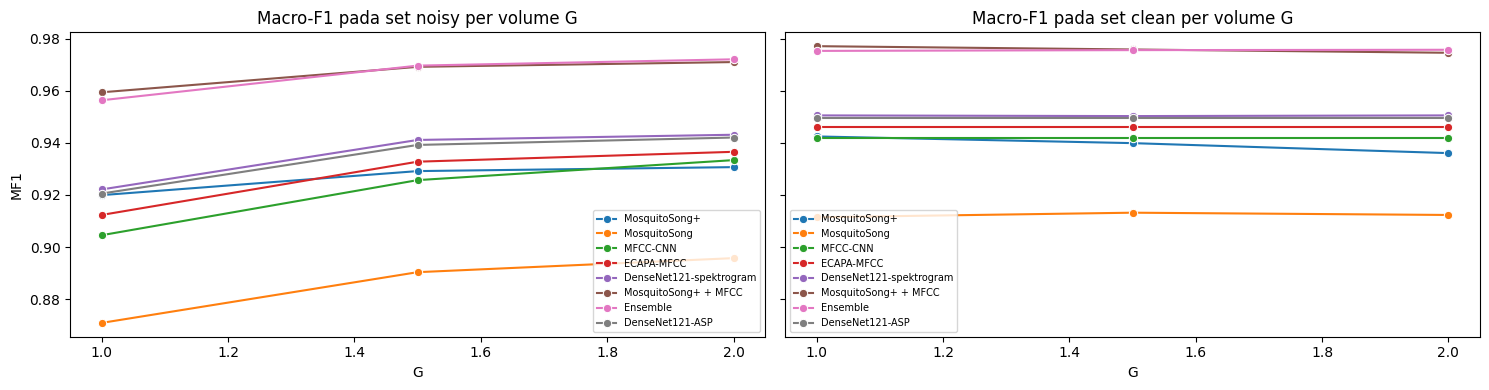

In [18]:
# MF1 per G dan per kondisi test (noisy vs clean)
rows = []
for m in ORDER:
    for g in GAINS:
        for cond in ('noisy', 'clean'):
            s = summary(*collect(METHODS[m], gains=(g,), include_noisy=cond == 'noisy', include_clean=cond == 'clean'))
            rows.append({'metode': LBL(m), 'G': g, 'kondisi': cond, 'MF1': s['MF1'], 'ACC': s['ACC']})
by_g = pd.DataFrame(rows)
by_g.to_csv('figures/03_mf1_per_G.csv', index=False)
display(by_g.pivot_table(index='metode', columns=['kondisi', 'G'], values='MF1').reindex([LBL(m) for m in ORDER]).round(3))
fig, ax = plt.subplots(1, 2, figsize=(15, 4), sharey=True)
for a, cond in zip(ax, ('noisy', 'clean')):
    sns.lineplot(data=by_g[by_g.kondisi == cond], x='G', y='MF1', hue='metode', marker='o', ax=a)
    a.set(title=f'Macro-F1 pada set {cond} per volume G'); a.legend(fontsize=7)
plt.tight_layout(); plt.savefig('figures/03_mf1_per_G.png', dpi=150); plt.show()

## 6. Uji Hipotesis

- **H1** (replikasi): MosquitoSong+ > MosquitoSong, satu sisi. Mann-Whitney (seperti paper) dan *corrected resampled t-test*.
- **H2-H4** (keluarga utama, dua sisi): setiap pembanding vs MosquitoSong+ pada MF1 per fold. Uji utama *corrected resampled t-test* (Nadeau & Bengio, 2003; varians dikalikan 1/k + ρ/(1-ρ), ρ = 1/10) karena set train antar fold saling tumpang tindih sehingga paired t-test biasa terlalu liberal. Koreksi Holm atas seluruh keluarga (maksimal 5 perbandingan). Wilcoxon dan paired t-test biasa dilaporkan sebagai pembanding.
- **Eksploratori:** DenseNet121-ASP vs DenseNet121, hanya selisih dan CI 95 %, di luar keluarga Holm.

In [19]:
def corrected_ttest(d, rho=0.1, alternative='two-sided'):
    """Corrected resampled t-test (Nadeau & Bengio, 2003) untuk selisih skor per fold d (k fold, test/train = rho/(1-rho)).
    Varians dikoreksi dengan faktor (1/k + rho/(1-rho)) karena set train antar fold saling tumpang tindih."""
    d = np.asarray(d, float); k = len(d)
    se = np.sqrt((1 / k + rho / (1 - rho)) * d.var(ddof=1))
    t = d.mean() / se if se > 0 else np.inf * np.sign(d.mean())
    p = {'two-sided': 2 * stats.t.sf(abs(t), k - 1), 'greater': stats.t.sf(t, k - 1), 'less': stats.t.cdf(t, k - 1)}[alternative]
    tq = stats.t.ppf(.975, k - 1)
    return t, p, (d.mean() - tq * se, d.mean() + tq * se)


def holm(p):
    """Koreksi Holm-Bonferroni (step-down)."""
    p = np.asarray(p, float); order = np.argsort(p); adj = np.empty_like(p); running = 0
    for i, j in enumerate(order):
        running = max(running, (len(p) - i) * p[j]); adj[j] = min(1, running)
    return adj


def compare(a, b, masks=None, metric='MF1', alternative='two-sided'):
    """Bandingkan metode b terhadap acuan a pada fold yang sama: selisih MF1 per fold (b - a)."""
    A, B = per_fold(METHODS[a], masks)[metric], per_fold(METHODS[b], masks)[metric]
    common = A.index.intersection(B.index)
    d = (B[common] - A[common]).values
    t, p_c, ci = corrected_ttest(d, RHO, alternative)
    return {'n fold': len(common), 'Δ rerata': d.mean(), '95% CI terkoreksi': f'[{ci[0]:+.4f}, {ci[1]:+.4f}]',
            'menang': f'{(d > 0).sum()}/{len(d)}', 't terkoreksi': t, 'p terkoreksi': p_c,
            'p paired t': stats.ttest_rel(B[common], A[common], alternative=alternative).pvalue,
            'p Wilcoxon': stats.wilcoxon(d, alternative=alternative).pvalue if np.any(d != 0) else 1.0}


rows = []
if OLD in METHODS:                                          # H1: replikasi klaim paper (satu sisi)
    r = compare(OLD, BASELINE, alternative='greater')
    r['p Mann-Whitney'] = stats.mannwhitneyu(PF[BASELINE].MF1, PF[OLD].MF1, alternative='greater').pvalue
    rows.append({'hipotesis': 'H1', 'pembanding': LBL(BASELINE), 'acuan': LBL(OLD), **r})
family = []
for m in COMPARATORS:                                       # keluarga H2-H4 (dua sisi), Holm atas corrected p
    family.append({'hipotesis': HYPOTHESIS[m], 'pembanding': LBL(m), 'acuan': LBL(BASELINE), **compare(BASELINE, m)})
for row, adj in zip(family, holm([r['p terkoreksi'] for r in family]) if family else []):
    row['p terkoreksi (Holm)'] = adj
rows += family
if {'densenet121', 'densenet121_asp'} <= METHODS.keys():    # eksploratori: hanya selisih + CI
    rows.append({'hipotesis': 'eksploratori', 'pembanding': LBL('densenet121_asp'), 'acuan': LBL('densenet121'),
                 **compare('densenet121', 'densenet121_asp')})
TESTS_TAB = pd.DataFrame(rows)
TESTS_TAB.to_csv('figures/03_uji_hipotesis.csv', index=False)
TESTS_TAB.round(4)

,hipotesis,pembanding,acuan,n fold,Δ rerata,95% CI terkoreksi,menang,t terkoreksi,p terkoreksi,p paired t,p Wilcoxon,p Mann-Whitney,p terkoreksi (Holm)
0,H1,MosquitoSong+,MosquitoSong,10,0.0335,"[+0.0204, +0.0467]",10/10,5.7816,0.0001,0.0000,0.0010,0.0129,NaN
1,H2,MFCC-CNN,MosquitoSong+,10,-0.0019,"[-0.0197, +0.0159]",3/10,-0.2370,0.8179,0.7384,0.4316,NaN,1.0000
2,H2,ECAPA-MFCC,MosquitoSong+,10,0.0029,"[-0.0203, +0.0261]",5/10,0.2792,0.7864,0.6945,0.9219,NaN,1.0000
3,H2,DenseNet121-spektrogram,MosquitoSong+,10,0.0096,"[-0.0158, +0.0350]",8/10,0.8575,0.4134,0.2443,0.2754,NaN,1.0000
4,H3,MosquitoSong+ + MFCC,MosquitoSong+,10,0.0383,"[+0.0205, +0.0560]",10/10,4.8702,0.0009,0.0001,0.0020,NaN,0.0035
5,H4,Ensemble,MosquitoSong+,10,0.0376,"[+0.0222, +0.0530]",10/10,5.5072,0.0004,0.0000,0.0020,NaN,0.0019
6,eksploratori,DenseNet121-ASP,DenseNet121-spektrogram,10,-0.0012,"[-0.0306, +0.0282]",3/10,-0.0904,0.9299,0.8983,0.6953,NaN,NaN


## 7. Sensitivitas Kebocoran

Sebagian epoch test berasal dari file rekaman yang juga terpotong ke train di fold yang sama (EDA notebook 01, bagian 5.10). Subset **bebas-kebocoran (file)** membuang epoch test tersebut; subset **ketat** juga membuang epoch yang rekaman kembar kondensernya ada di train.

In [20]:
# Subset test bebas-kebocoran per fold (urutan identik dengan preds['y'])
E = load_epochs('data/mosquito_recordings')
totals = count_per_group(E)
E_files = epoch_files('data/mosquito_recordings')
E_idx = [(k, lab, low, np.array([i], dtype=np.float64)) for i, (k, lab, low, _) in enumerate(E)]
twin = lambda f: f.replace('_LowMic', '').lower()
MASK_FILE, MASK_STRICT, rows = {}, {}, []
Y_BASE = {d['fold']: d['y'] for d in METHODS[BASELINE]}
for k in range(10):
    s = split_fold(E_idx, totals, k)
    tr, te = s['train'][0][:, 0].astype(int), s['test'][0][:, 0].astype(int)
    if k in Y_BASE:                                         # urutan test harus sama dengan preds
        assert (encode(s['test'][1]) == Y_BASE[k]).all()
    train_files = {E_files[i] for i in tr}
    train_twins = {twin(f) for f in train_files if '_LowMic' not in f}
    MASK_FILE[k] = np.array([E_files[i] not in train_files for i in te])
    MASK_STRICT[k] = MASK_FILE[k] & np.array([twin(E_files[i]) not in train_twins for i in te])
    rows.append({'fold': k, 'test': len(te), 'bebas-kebocoran (file)': MASK_FILE[k].sum(),
                 'bebas-kebocoran ketat (file + kembar kondenser)': MASK_STRICT[k].sum()})
leak_tab = pd.DataFrame(rows).set_index('fold')
leak_tab.loc['total'] = leak_tab.sum()
leak_tab['% file'] = (100 * leak_tab['bebas-kebocoran (file)'] / leak_tab.test).round(1)
leak_tab['% ketat'] = (100 * leak_tab['bebas-kebocoran ketat (file + kembar kondenser)'] / leak_tab.test).round(1)
leak_tab

,test,bebas-kebocoran (file),bebas-kebocoran ketat (file + kembar kondenser),% file,% ketat
fold,,,,,
0,600,465,365,77.5,60.8
1,600,414,307,69.0,51.2
2,600,459,322,76.5,53.7
3,600,488,382,81.3,63.7
4,600,437,387,72.8,64.5
5,600,465,446,77.5,74.3
6,600,437,406,72.8,67.7
7,600,432,356,72.0,59.3
8,600,399,349,66.5,58.2


In [21]:
# Sensitivitas kebocoran: metrik dan uji diulang pada subset test bebas-kebocoran
rows = []
for m in ORDER:
    rows.append({'metode': LBL(m), 'MF1 semua test': summary(*collect(METHODS[m]))['MF1'],
                 'MF1 bebas-kebocoran (file)': summary(*collect(METHODS[m], masks=MASK_FILE))['MF1'],
                 'MF1 bebas-kebocoran ketat': summary(*collect(METHODS[m], masks=MASK_STRICT))['MF1']})
LEAK_TAB = pd.DataFrame(rows).set_index('metode')
LEAK_TAB['Δ (file - semua)'] = LEAK_TAB['MF1 bebas-kebocoran (file)'] - LEAK_TAB['MF1 semua test']
LEAK_TAB.to_csv('figures/03_kebocoran.csv'); display(LEAK_TAB.round(4))

leak_tests = pd.DataFrame([{'pembanding': LBL(m), **compare(BASELINE, m, masks=MASK_FILE)} for m in COMPARATORS])
if len(leak_tests):
    leak_tests['p terkoreksi (Holm)'] = holm(leak_tests['p terkoreksi'])
print('Uji pada subset bebas-kebocoran (file):'); leak_tests.round(4)

,MF1 semua test,MF1 bebas-kebocoran (file),MF1 bebas-kebocoran ketat,Δ (file - semua)
metode,,,,
MosquitoSong+,0.9330,0.9272,0.9182,-0.0058
MosquitoSong,0.8991,0.8936,0.8770,-0.0054
MFCC-CNN,0.9313,0.9282,0.9220,-0.0030
ECAPA-MFCC,0.9363,0.9289,0.9202,-0.0074
DenseNet121-spektrogram,0.9428,0.9383,0.9327,-0.0045
MosquitoSong+ + MFCC,0.9711,0.9680,0.9629,-0.0031
Ensemble,0.9707,0.9682,0.9641,-0.0024
DenseNet121-ASP,0.9415,0.9376,0.9361,-0.0039


Uji pada subset bebas-kebocoran (file):


,pembanding,n fold,Δ rerata,95% CI terkoreksi,menang,t terkoreksi,p terkoreksi,p paired t,p Wilcoxon,p terkoreksi (Holm)
0,MFCC-CNN,10,-0.0031,"[-0.0247, +0.0185]",3/10,-0.3225,0.7545,0.6505,0.3750,1.0000
1,ECAPA-MFCC,10,0.0015,"[-0.0257, +0.0287]",5/10,0.1238,0.9042,0.8613,0.9219,1.0000
2,DenseNet121-spektrogram,10,0.0115,"[-0.0178, +0.0407]",8/10,0.8866,0.3983,0.2298,0.2754,1.0000
3,MosquitoSong+ + MFCC,10,0.0402,"[+0.0216, +0.0589]",10/10,4.8825,0.0009,0.0001,0.0020,0.0035
4,Ensemble,10,0.0382,"[+0.0236, +0.0528]",10/10,5.9161,0.0002,0.0000,0.0020,0.0011


## 8. Kesimpulan per Kriteria

Sebuah pembanding dinyatakan **mengungguli MosquitoSong+** hanya bila ketiga syarat terpenuhi dan 10 fold lengkap:
1. MF1 gabungan lebih tinggi dari MosquitoSong+ replikasi dan dari 0,911 (paper);
2. *corrected resampled t-test* signifikan pada α = 0,05 setelah Holm, dengan selisih positif;
3. tetap unggul pada subset bebas-kebocoran.

In [22]:
# Kriteria "mengungguli MosquitoSong+" (ditetapkan di rencana sebelum eksperimen)
rows = []
fam_tests = TESTS_TAB[TESTS_TAB.hipotesis.isin(['H2', 'H3', 'H4'])].set_index('pembanding')
for m in COMPARATORS:
    t = fam_tests.loc[LBL(m)]
    c1 = MAIN.loc[LBL(m), 'MF1'] > max(MAIN.loc[LBL(BASELINE), 'MF1'], PAPER_MSPLUS['MF1'])
    c2 = (t['p terkoreksi (Holm)'] < ALPHA) and (t['Δ rerata'] > 0)
    c3 = LEAK_TAB.loc[LBL(m), 'MF1 bebas-kebocoran (file)'] > LEAK_TAB.loc[LBL(BASELINE), 'MF1 bebas-kebocoran (file)']
    rows.append({'metode': LBL(m), 'hipotesis': HYPOTHESIS[m], 'fold': int(t['n fold']),
                 '1. MF1 > MS+ replikasi & paper': c1, '2. signifikan (corrected t + Holm)': c2,
                 '3. unggul di subset bebas-kebocoran': c3, 'MENGUNGGULI MS+': c1 and c2 and c3 and t['n fold'] == 10})
VERDICT_TAB = pd.DataFrame(rows).set_index('metode') if rows else pd.DataFrame()
VERDICT_TAB.to_csv('figures/03_kesimpulan.csv'); VERDICT_TAB

,hipotesis,fold,1. MF1 > MS+ replikasi & paper,2. signifikan (corrected t + Holm),3. unggul di subset bebas-kebocoran,MENGUNGGULI MS+
metode,,,,,,
MFCC-CNN,H2,10,False,False,True,False
ECAPA-MFCC,H2,10,True,False,True,False
DenseNet121-spektrogram,H2,10,True,False,True,False
MosquitoSong+ + MFCC,H3,10,True,True,True,True
Ensemble,H4,10,True,True,True,True


## 9. Variansi Seed

In [23]:
# Variansi seed: pembanding dengan MF1 validation tertinggi, 2 seed tambahan pada fold 0-2
seed_rows, fold_sd = [], {}
for fam in FAMILY_RUNS:
    prefix = fam if len(FAMILY_RUNS[fam]) > 1 else FAMILY_RUNS[fam][0]
    seed_runs = [r for r in (f'{prefix}_s1', f'{prefix}_s2') if run_complete_folds(r)]
    if not seed_runs or fam not in METHODS:
        continue
    base, seen = per_fold(METHODS[fam])['MF1'], set()
    for r in seed_runs:
        for f, v in per_fold(load_run(r))['MF1'].items():
            seed_rows.append({'keluarga': LBL(fam), 'fold': f, 'seed': r[-2:], 'MF1': v}); seen.add(f)
    for f in sorted(seen & set(base.index)):
        seed_rows.append({'keluarga': LBL(fam), 'fold': f, 'seed': 's0 (42)', 'MF1': base[f]})
    fold_sd[LBL(fam)] = base.std()
if seed_rows:
    sd = pd.DataFrame(seed_rows).pivot_table(index=['keluarga', 'fold'], columns='seed', values='MF1')
    sd['sd antar seed'] = sd.std(axis=1)
    sd.to_csv('figures/03_variansi_seed.csv'); display(sd.round(4))
    for k, v in fold_sd.items():
        print(f"{k}: rerata sd antar seed {sd.loc[k, 'sd antar seed'].mean():.4f} vs sd antar fold {v:.4f}")
else:
    print('Belum ada run cek seed (tahap 4 notebook 02).')

seed                       s0 (42)      s1      s2  sd antar seed
keluarga             fold                                        
MosquitoSong+ + MFCC 0      0.9643  0.9720  0.9733         0.0049
                     1      0.9873  0.9912  0.9845         0.0034
                     2      0.9739  0.9714  0.9697         0.0021

MosquitoSong+ + MFCC: rerata sd antar seed 0.0034 vs sd antar fold 0.0145


## 10. Visualisasi

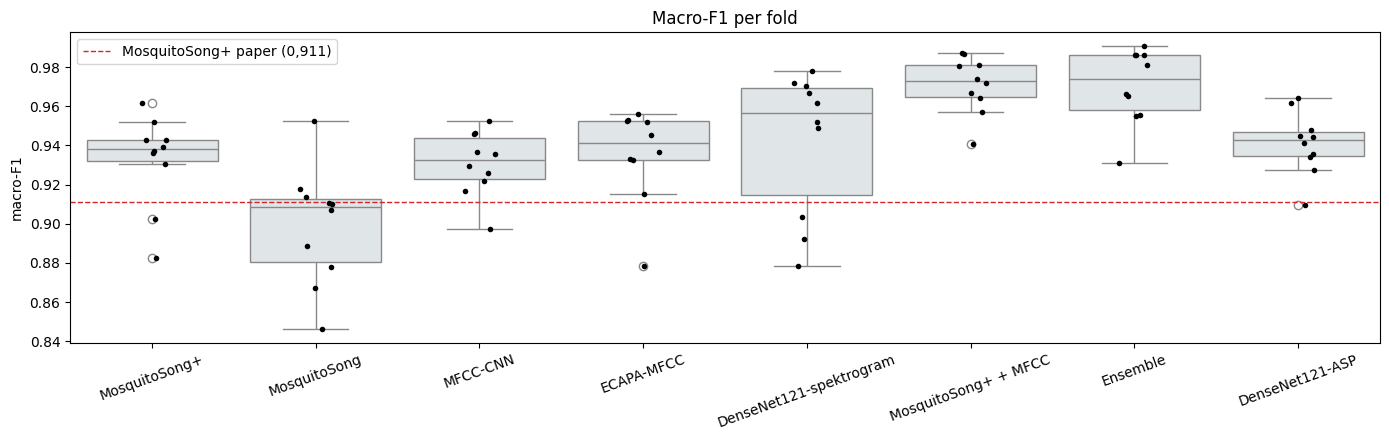

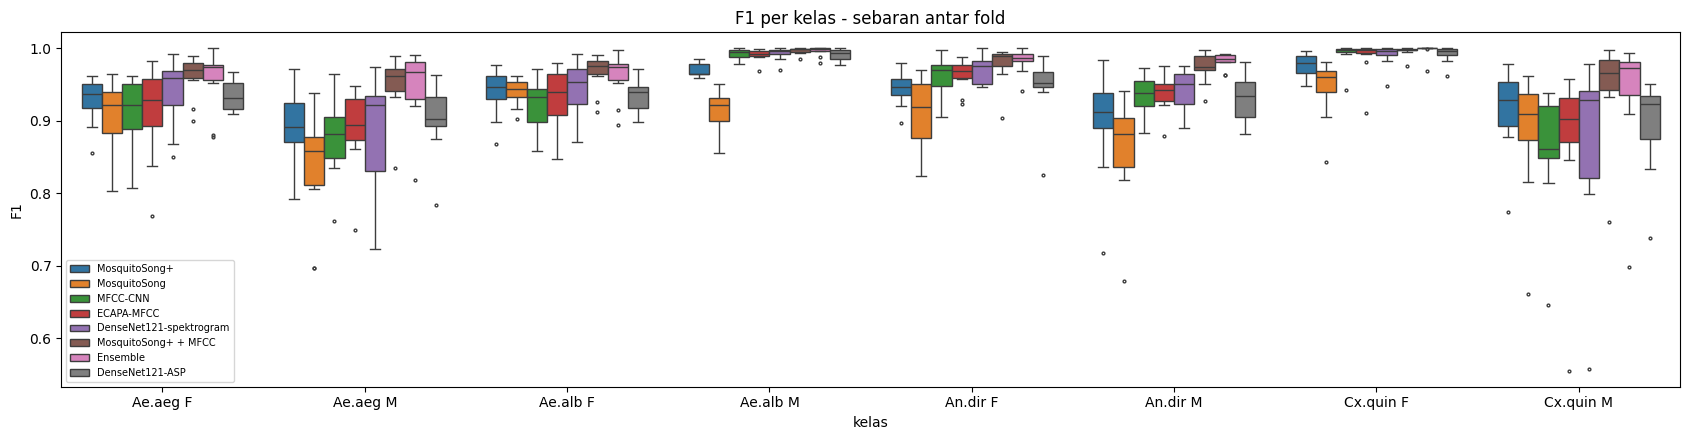

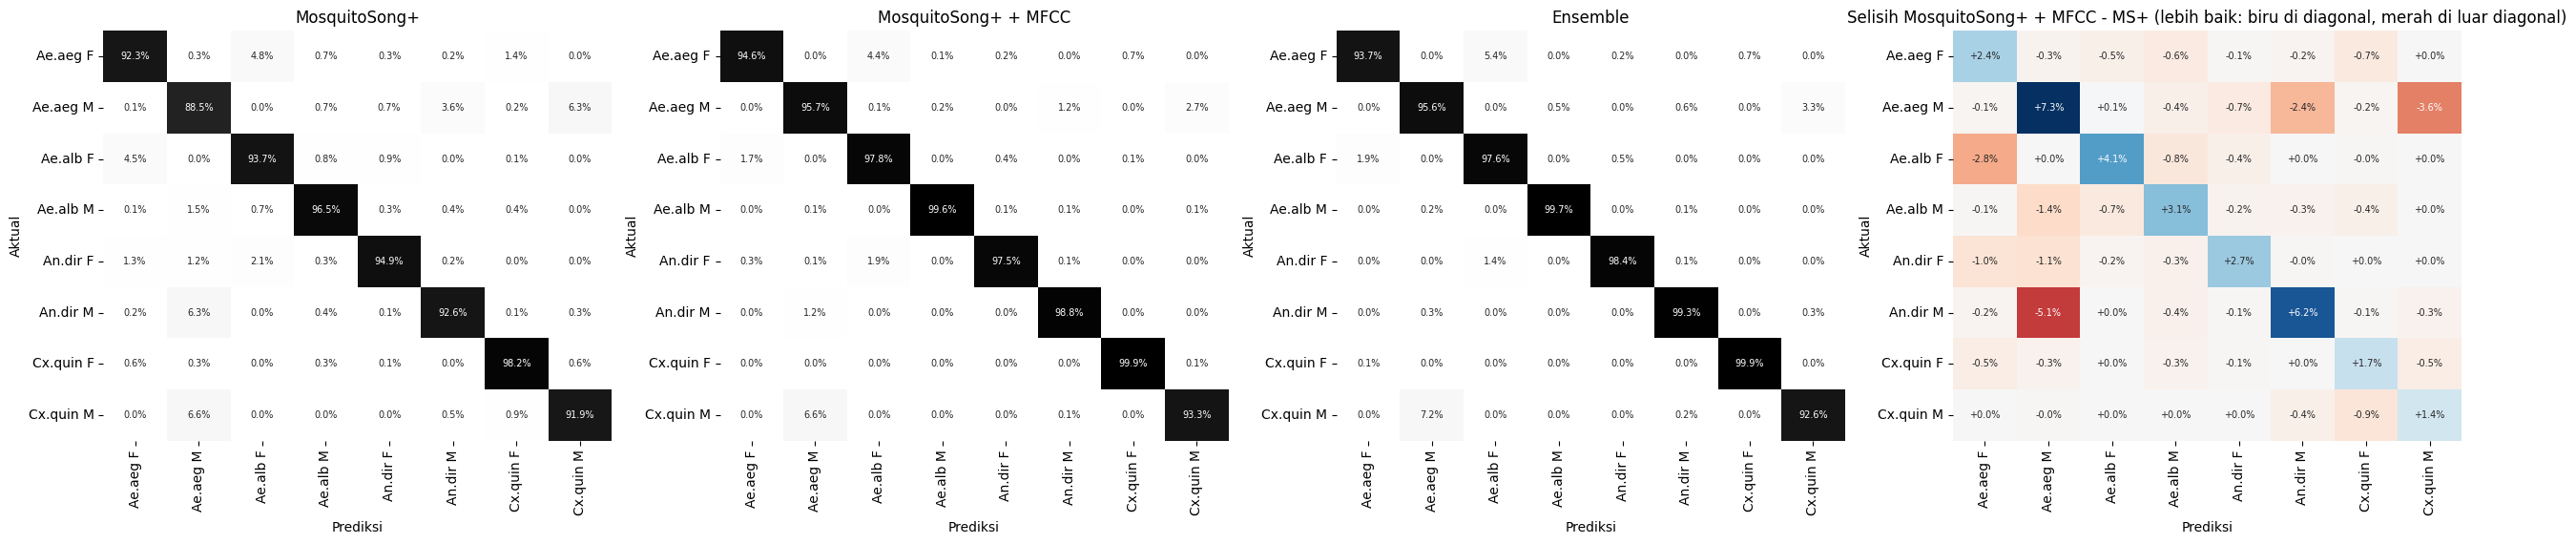

In [24]:
# Boxplot MF1 per fold, F1 per kelas, dan confusion matrix
pf_long = pd.concat([PF[m].reset_index().assign(metode=LBL(m)) for m in ORDER])
fig, ax = plt.subplots(figsize=(14, 4.5))
sns.boxplot(data=pf_long, x='metode', y='MF1', ax=ax, color='#dfe6e9')
sns.stripplot(data=pf_long, x='metode', y='MF1', ax=ax, color='k', size=4)
ax.axhline(PAPER_MSPLUS['MF1'], ls='--', color='C3', lw=1, label='MosquitoSong+ paper (0,911)')
ax.set(title='Macro-F1 per fold', xlabel='', ylabel='macro-F1'); ax.tick_params(axis='x', rotation=20); ax.legend()
plt.tight_layout(); plt.savefig('figures/03_boxplot_mf1.png', dpi=150); plt.show()

long = pf_long.melt(id_vars=['fold', 'metode'], value_vars=[f'F1 {c}' for c in SHORT], var_name='kelas', value_name='F1')
long['kelas'] = long.kelas.str[3:]
plt.figure(figsize=(17, 4.5)); sns.boxplot(data=long, x='kelas', y='F1', hue='metode', fliersize=2)
plt.title('F1 per kelas - sebaran antar fold'); plt.legend(fontsize=7, loc='lower left'); plt.tight_layout()
plt.savefig('figures/03_boxplot_f1_kelas.png', dpi=150); plt.show()

best = MAIN.drop(index=[LBL(m) for m in (BASELINE, OLD, 'released_mosquitosong', 'densenet121_asp') if m in METHODS], errors='ignore')
best_m = next((m for m in ORDER if len(best) and LBL(m) == best.MF1.idxmax()), None)
panels = [m for m in (BASELINE, best_m) if m] + (['ensemble'] if 'ensemble' in METHODS and best_m != 'ensemble' else [])
fig, axes = plt.subplots(1, len(panels) + (1 if best_m else 0), figsize=(6.5 * (len(panels) + 1), 5.8))
axes = np.atleast_1d(axes)
for a, m in zip(axes, panels):
    sns.heatmap(confmat(METHODS[m]), annot=True, fmt='.1%', cmap='Greys', cbar=False, vmin=0, vmax=1,
                xticklabels=SHORT, yticklabels=SHORT, ax=a, annot_kws={'size': 7})
    a.set(title=LBL(m), xlabel='Prediksi', ylabel='Aktual')
if best_m:
    diff = confmat(METHODS[best_m]) - confmat(METHODS[BASELINE])
    sns.heatmap(diff, annot=True, fmt='+.1%', cmap='RdBu', center=0, cbar=False, xticklabels=SHORT, yticklabels=SHORT,
                ax=axes[-1], annot_kws={'size': 7})
    axes[-1].set(title=f'Selisih {LBL(best_m)} - MS+ (lebih baik: biru di diagonal, merah di luar diagonal)', xlabel='Prediksi', ylabel='Aktual')
plt.tight_layout(); plt.savefig('figures/03_confusion_matrices.png', dpi=130); plt.show()

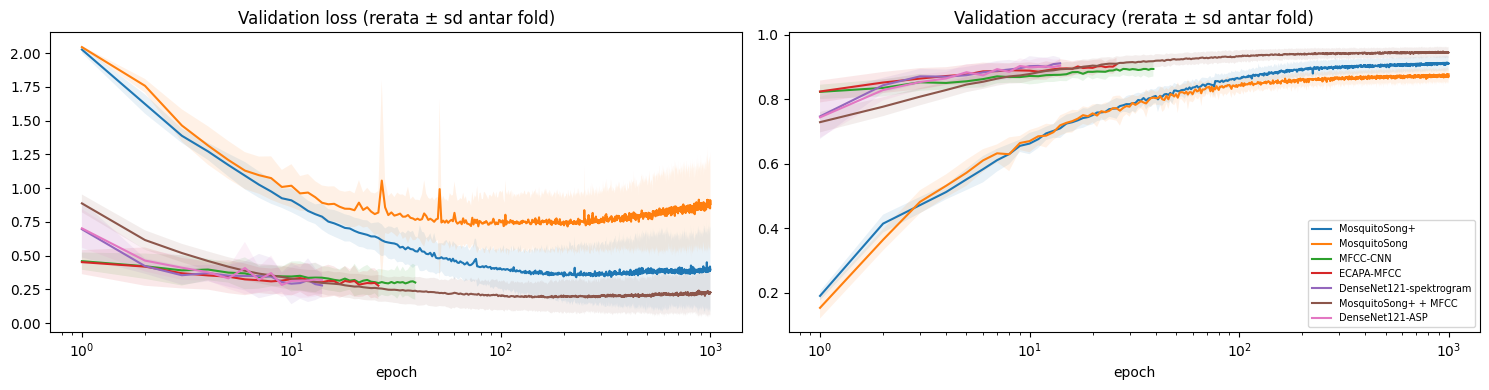

In [25]:
# Kurva validasi (varian terpilih per fold) untuk semua metode yang dilatih
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
for m in [x for x in ORDER if x not in ('released_mosquitosong', 'ensemble')]:
    H = [hist(d['run'] if 'run' in d else (ASP_RUN if m == 'densenet121_asp' else m), d['fold']) for d in METHODS[m]]
    n_ep = min(len(h) for h in H); ep = np.arange(1, n_ep + 1)
    for a, col in zip(axes, ('val_loss', 'val_acc')):
        v = np.stack([h[col].values[:n_ep] for h in H]); a.plot(ep, v.mean(0), label=LBL(m))
        a.fill_between(ep, v.mean(0) - v.std(0), v.mean(0) + v.std(0), alpha=.1)
axes[0].set(title='Validation loss (rerata ± sd antar fold)', xlabel='epoch', xscale='log')
axes[1].set(title='Validation accuracy (rerata ± sd antar fold)', xlabel='epoch', xscale='log'); axes[1].legend(fontsize=7)
plt.tight_layout(); plt.savefig('figures/03_kurva_validasi.png', dpi=150); plt.show()

## 11. Biaya Komputasi

Waktu training per fold untuk keluarga dengan dua lr dijumlahkan dari kedua varian, karena keduanya harus dilatih untuk memilih lr. Latensi diukur di CPU notebook ini (tanpa GPU), mendekati skenario perangkat IoT; ensemble = jumlah anggotanya.

,parameter,latensi 1 sampel CPU (ms),latensi batch 64 CPU (ms/sampel),"training per fold (menit, GPU)",MF1
MosquitoSong+,348808.0,1.548,0.044,91.538,0.933
MosquitoSong,221576.0,1.328,0.035,80.889,0.899
MFCC-CNN,112936.0,1.965,0.038,11.250,0.931
ECAPA-MFCC,366472.0,4.795,0.088,13.238,0.936
DenseNet121-spektrogram,7169736.0,17.473,1.053,65.565,0.943
MosquitoSong+ + MFCC,370696.0,1.872,0.033,91.736,0.971
DenseNet121-ASP,7572232.0,18.178,1.134,33.614,0.942
Ensemble,8368648.0,27.653,1.256,273.326,0.971


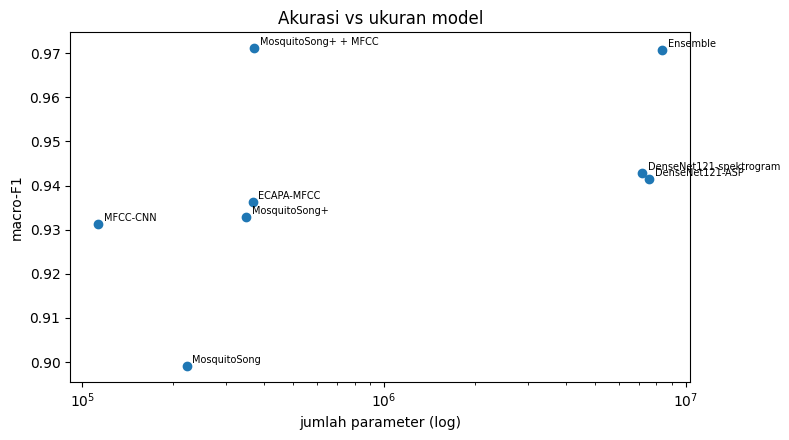

In [26]:
# Biaya: parameter, waktu training per fold (termasuk semua varian lr yang dilatih untuk pemilihan), latensi CPU
def train_minutes(m):
    if m in FAMILY_RUNS:
        runs = FAMILY_RUNS[m]
    elif m == 'densenet121_asp':
        runs = [ASP_RUN]
    else:
        runs = [m]
    per_run = [np.mean([cfgj(r, f).get('train_time_s', 0) for f in run_complete_folds(r)]) / 60 for r in runs if run_complete_folds(r)]
    return sum(per_run)


def latency(model, batch, reps=20):
    x = np.random.randn(batch, TARGET, 1).astype('float32')
    f = tf.function(lambda v: model(v, training=False))
    f(x); t = time.perf_counter()
    for _ in range(reps):
        f(x)
    return (time.perf_counter() - t) / reps * 1000


MODEL_OF = {BASELINE: 'mosquitosong_plus', OLD: 'mosquitosong', 'released_mosquitosong': 'mosquitosong',
            'mfcc_cnn': 'mfcc_cnn', 'ecapa_mfcc': 'ecapa_mfcc', 'densenet121': 'densenet121',
            'mosquitosong_plus_mfcc': 'mosquitosong_plus_mfcc', 'densenet121_asp': 'densenet121_asp'}
cost = {}
for m in [x for x in ORDER if x != 'ensemble']:
    model = build_model(MODEL_OF[m], pretrained=False)
    cost[m] = {'parameter': model.count_params(), 'latensi 1 sampel CPU (ms)': latency(model, 1),
               'latensi batch 64 CPU (ms/sampel)': latency(model, 64, 5) / 64, 'training per fold (menit, GPU)': train_minutes(m)}
    keras.backend.clear_session()
if 'ensemble' in METHODS:
    cost['ensemble'] = {k: sum(cost[x][k] for x in members) for k in next(iter(cost.values()))}
COST_TAB = pd.DataFrame(cost).T.rename(index=LBL)
COST_TAB['MF1'] = MAIN['MF1']
COST_TAB.to_csv('figures/03_biaya.csv'); display(COST_TAB.round(3))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(COST_TAB.parameter, COST_TAB.MF1)
for name, r in COST_TAB.iterrows():
    ax.annotate(name, (r.parameter, r.MF1), fontsize=7, xytext=(4, 2), textcoords='offset points')
ax.set(xscale='log', xlabel='jumlah parameter (log)', ylabel='macro-F1', title='Akurasi vs ukuran model')
plt.tight_layout(); plt.savefig('figures/03_mf1_vs_parameter.png', dpi=150); plt.show()

## 12. Artefak

`figures/` berisi semua tabel (CSV) dan gambar untuk artikel; `results.zip` mengemasnya bersama `requirements.txt`.

| File | Isi |
|---|---|
| `03_tabel_utama.csv` | ACC, MF1, rerata ± sd per fold, selisih vs MS+ dan paper |
| `03_uji_hipotesis.csv` | H1, H2-H4 (corrected t, Holm, Wilcoxon, paired t), eksploratori |
| `03_kebocoran.csv` | MF1 pada subset bebas-kebocoran |
| `03_kesimpulan.csv` | Pemenuhan tiga kriteria per pembanding |
| `03_biaya.csv` | Parameter, waktu training, latensi |
| `03_*.png` | Boxplot, F1 per kelas, confusion matrix, kurva validasi, MF1 per G, MF1 vs parameter |

In [27]:
# Ekspor lingkungan (requirements) dan kemas semua artefak
import subprocess, zipfile
with open('requirements.txt', 'w') as f:
    f.write(subprocess.run([sys.executable, '-m', 'pip', 'freeze'], capture_output=True, text=True).stdout)
with zipfile.ZipFile('results.zip', 'w', zipfile.ZIP_DEFLATED) as z:
    for pat in ('figures/*', 'logs/*', 'mosq_lib.py', 'requirements.txt'):
        for f in glob.glob(pat):
            if os.path.isfile(f):
                z.write(f)
print(f"results.zip: {os.path.getsize('results.zip')/1e6:.1f} MB | requirements.txt: "
      f"{sum(1 for _ in open('requirements.txt'))} paket")

results.zip: 0.7 MB | requirements.txt: 936 paket
